# Day 3 lecture: Text mining

<p class="lead">
Period 3 of Day 3, after the midterm, and the bridge to Lab 3. How a business turns free text into numbers it can act on: structured and unstructured data, the text-mining pipeline, tokenising and normalising, stop words and why "not" must sometimes stay, word frequency and n-grams, word clouds and their limits, TF-IDF, how the VADER sentiment scorer works and where it fails, checking scores against human labels, and turning scores into a decision without harming the people who wrote the text.
</p>

Run each code cell with **Shift + Enter**, in order. The examples use **forty synthetic hotel reviews** written for this lecture (a fictional two-site hotel, the "Lakeside Inn"), each with the guest's star rating. Lab 3 uses a different set of product reviews; this lecture deliberately does **not** use them, so that you practise each step here and apply it yourself in the lab.

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder; NLTK reads its word lists from `data/nltk_data`, so nothing is downloaded.
- **Route A (Try JupyterLab):** upload this notebook, run `%pip install nltk wordcloud scikit-learn` in a first cell, and replace the setup cell with the NLTK download cell from GAP's Lab 3 (see the [Lab 3 guide](guides/lab3_text_mining.md), Route A).

---

## What you will be able to do

1. Explain the difference between **structured and unstructured** data, and describe the steps of a **text-mining pipeline**.
2. **Tokenise** and **normalise** text, remove **stop words**, and say when removing a word such as "not" changes the meaning.
3. Count **word frequencies** and **n-grams**, and explain what a **word cloud** can and cannot show.
4. Explain the idea behind **stemming**, **lemmatisation** and **TF-IDF**.
5. Explain how the **VADER** lexicon scores a sentence (negation, intensifiers, "but", capitals and punctuation), and predict where it will fail.
6. **Validate** sentiment scores against human labels before trusting them.
7. Turn text-mining results into a **decision**, and name the **ethical** risks of mining customer text.

This lecture has one period (P3), so it has a **core path** and **extensions**. Teach the core in P3; the extensions are for a later study block, faster students, or self-study.

| Part | Topic | Path |
|---|---|---|
| 1 | Structured and unstructured data | Core |
| 2 | The pipeline: tokenising and normalising | Core |
| 3 | Stop words, and when to keep "not" | Core |
| 4 | Frequency and n-grams | Core |
| 5 | Word clouds and their limits | Core |
| 6 | How VADER scores text | Core |
| 7 | Where VADER fails | Core |
| 8 | Validating scores against labels | Core |
| 9 | From scores to decisions | Core |
| 10 | Stemming and lemmatisation | Extension |
| 11 | TF-IDF | Extension |
| 12 | Lexicon or machine learning? | Extension |
| 13 | Ethics of mining customer text | Core (summary) and extension |
| 14 | Business case | Extension |
| 15 | Lab 3 briefing | Core |
| 16 | Practice, quiz and summary | Self-study |

> **Reading**
>
> Read Chapter 3 of the course reading packet for the preprocessing pipeline, the five core text-mining techniques, the difference between text *mining* (finding a pattern) and text *analytics* (interpreting it for a decision), and why a lexicon-based scorer can call a clearly negative sentence neutral. This lecture adds negation handling, n-grams, TF-IDF, VADER's rules, validation against labels, decision rules and ethics.

### Setup

The first cell points NLTK at the course's offline word lists. Run it once at the start of every session.

In [1]:
import zipfile
from pathlib import Path

import nltk

NLTK_DIR = Path("data/nltk_data").resolve()
if not (NLTK_DIR / "tokenizers" / "punkt_tab").exists():
    with zipfile.ZipFile(NLTK_DIR / "tokenizers" / "punkt_tab.zip") as z:
        z.extractall(NLTK_DIR / "tokenizers")
nltk.data.path.insert(0, str(NLTK_DIR))

In [2]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from wordcloud import WordCloud

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
# Okabe and Ito colour-blind-safe colours: blue for positive, orange for negative, grey for neutral
BLUE, ORANGE, GREY = "#0072B2", "#D55E00", "#B0B0B0"

# Forty synthetic reviews of a fictional hotel, written for this lecture: (stars, text)
REVIEWS = [
    (5, "Lovely stay! The staff were friendly and the breakfast was excellent."),
    (4, "Clean room and a comfortable bed. Breakfast was good but the coffee was weak."),
    (1, "The room was tiny and the walls were paper thin. We heard every word next door."),
    (2, "Check-in took forty minutes. The receptionist was polite, but nobody could find our booking."),
    (5, "Best hotel we have stayed in this year. Amazing view of the lake and a really comfortable bed."),
    (1, "Great, the lift broke again. Loved carrying our bags up five flights of stairs."),
    (3, "The room was fine. No frills at all, but the location is convenient for the station."),
    (2, "The shower was lukewarm every morning and the air conditioning rattled all night."),
    (4, "Friendly staff and a quiet room. The breakfast could be better."),
    (1, "Never again. The bathroom had mould and the sheets smelled of smoke."),
    (5, "The staff went out of their way to help us. Spotless room and a delicious breakfast!"),
    (3, "Average hotel. The bed was comfortable but the room was small and dark."),
    (2, "Not clean. Hair in the sink and dust under the bed."),
    (4, "Good value for money. The room was small but clean and the staff were helpful."),
    (1, "We waited an hour for a room that was supposed to be ready. The manager was rude and offered nothing."),
    (5, "Wonderful location, super friendly staff and the best breakfast buffet in town."),
    (3, "Breakfast was okay. Parking was expensive."),
    (2, "The wifi dropped every ten minutes, so I could not work from the room."),
    (4, "The bed was very comfortable and the room was quiet. Check-in was a bit slow."),
    (1, "Overbooked. They moved us to another hotel across town at midnight."),
    (5, "Absolutely loved it! The lake view from our balcony was stunning."),
    (2, "The room was not as advertised. No balcony and the view was a car park."),
    (3, "Staff were helpful. The room itself was dated and the carpet was worn."),
    (4, "Lovely breakfast and a helpful concierge. The lift was slow."),
    (1, "Noisy, dirty and overpriced. The worst night's sleep I've had in years."),
    (5, "Everything was perfect, from check-in to check-out. We will definitely come back."),
    (2, "The bed was hard and the pillows were flat. I woke up with a sore back."),
    (3, "It was fine for one night. I would not stay longer."),
    (4, "The staff were friendly and the room was clean, but the walls were thin."),
    (1, "Cockroach in the bathroom on the first night. Reception just shrugged."),
    (5, "Great service, great food, great location. Highly recommend!"),
    (2, "Breakfast ran out of eggs by 8am and nobody refilled the coffee."),
    (3, "Decent room, small bathroom. The staff were neither friendly nor rude."),
    (4, "Quiet, clean and close to the station. The breakfast was a little expensive."),
    (1, "They charged my card twice and it took three weeks to get a refund."),
    (5, "A gem! Cosy room, kind staff and a breakfast worth getting up for."),
    (2, "The heating did not work and the extra blanket never arrived."),
    (3, "The room was clean. The view was of a wall."),
    (4, "Comfortable bed and a great shower. The wifi was a little slow."),
    (2, "Good location, but the room smelled damp and the window would not close."),
]
reviews = pd.DataFrame(REVIEWS, columns=["stars", "text"])
reviews.insert(0, "review_id", range(1, len(reviews) + 1))
reviews.insert(1, "site", ["Old Town" if i % 3 == 0 else "Riverside" for i in range(len(reviews))])
print(reviews.shape)
reviews.head()

(40, 4)


,review_id,site,stars,text
0,1,Old Town,5,Lovely stay! The staff were friendly and the breakfast was excellent.
1,2,Riverside,4,Clean room and a comfortable bed. Breakfast was good but the coffee was weak.
2,3,Riverside,1,The room was tiny and the walls were paper thin. We heard every word next door.
3,4,Old Town,2,"Check-in took forty minutes. The receptionist was polite, but nobody could find our booking."
4,5,Riverside,5,Best hotel we have stayed in this year. Amazing view of the lake and a really comfortable bed.


---

## Part 1: Structured and unstructured data (core)

**Structured** data fits a fixed table: every row has the same columns, and each column has one type (a number, a date, a category). The `stars` column above is structured: you can average it, group it and chart it at once. **Unstructured** data has no fixed fields. A review, an email, a support chat or a call transcript carries its meaning in the choice and order of words, and its length varies from three words to three pages.

| | Structured | Unstructured |
|---|---|---|
| Example | Star rating, price, check-in date | Review text, complaint email, social-media post |
| Shape | Fixed columns and types | Free-length strings |
| Summarise with | `describe()`, `groupby()`, a pivot table | Nothing, until it is converted |
| Share of what organisations collect | Smaller | Larger (often quoted as about 80%) |
| What it tells you | **How much** (3 stars) | **Why** (the shower was cold) |

Between the two sits **semi-structured** data, such as a JSON order record with a free-text "notes" field.

Text mining is the conversion from the right-hand column to the left: it creates new structured columns (counts, flags, scores) from text, after which every tool from Days 1 and 2 applies again.

> **Predict, then run.** `describe()` works on `stars`. What do you expect it to say about the `text` column?

In [3]:
print(reviews["stars"].describe().round(2))
print()
print(reviews["text"].describe())

count    40.00
mean      2.98
std       1.44
min       1.00
25%       2.00
50%       3.00
75%       4.00
max       5.00
Name: stars, dtype: float64

count                                                                        40
unique                                                                       40
top       Lovely stay! The staff were friendly and the breakfast was excellent.
freq                                                                          1
Name: text, dtype: object


For text, `describe()` can only count: 40 values, 40 unique, the "top" is just one of them. To learn anything we must **engineer features**. Even very simple features are already useful:

In [4]:
reviews["n_words"] = reviews["text"].str.split().str.len()
reviews["mentions_breakfast"] = reviews["text"].str.lower().str.contains("breakfast")
reviews.groupby("mentions_breakfast")[["stars", "n_words"]].agg(["mean", "count"]).round(2)

stars       n_words      
                    mean count    mean count
mentions_breakfast                          
False                2.6    30    13.2    30
True                 4.1    10    11.8    10

Two new structured columns, made from text in two lines. The rest of the lecture does the same thing more carefully.

---

## Part 2: The pipeline: tokenising and normalising (core)

Every text-mining project follows roughly the same pipeline. The order matters: each step works on the output of the one before.

| Step | What it does | Example |
|---|---|---|
| 1. Collect | Gather the text and its context (date, site, rating) | Export reviews with their star ratings |
| 2. Clean | Remove markup, fix encodings, mask personal data | Strip HTML; replace e-mail addresses with `[EMAIL]` |
| 3. **Tokenise** | Split text into units (tokens) | `"wasn't clean"` → `was`, `n't`, `clean` |
| 4. **Normalise** | Make variants of a word match | `Breakfast`, `BREAKFAST` → `breakfast` |
| 5. **Filter** | Drop tokens that carry no topic | Remove `the`, `and`, punctuation |
| 6. Reduce (optional) | Stem or lemmatise | `rooms` → `room` |
| 7. **Represent** | Turn tokens into numbers | Counts, n-grams, TF-IDF, a sentiment score |
| 8. Analyse | Find the pattern | Top words, sentiment by site, topics |
| 9. **Validate** | Check against human judgement | Compare scores with star ratings |
| 10. Decide | Interpret the pattern for an action | Fix the showers at Riverside first |

Steps 1 to 8 are **text mining**; step 10 is **text analytics**, the interpretation for a decision. Step 9 is the one most often skipped.

### Tokenising

> **Predict, then run.** Splitting on spaces is the simplest tokeniser. What will go wrong with the review below?

In [5]:
example = reviews.loc[3, "text"]   # review 4
print(example)
print()
print("split():      ", example.split())
print("word_tokenize:", word_tokenize(example))

Check-in took forty minutes. The receptionist was polite, but nobody could find our booking.

split():       ['Check-in', 'took', 'forty', 'minutes.', 'The', 'receptionist', 'was', 'polite,', 'but', 'nobody', 'could', 'find', 'our', 'booking.']
word_tokenize: ['Check-in', 'took', 'forty', 'minutes', '.', 'The', 'receptionist', 'was', 'polite', ',', 'but', 'nobody', 'could', 'find', 'our', 'booking', '.']


`split()` leaves punctuation stuck to words (`minutes.` and `minutes` would be counted as different words) and keeps `Check-in` and `booking.` whole. NLTK's `word_tokenize` separates punctuation and handles contractions in a consistent way: it splits **"wasn't"** into `was` and `n't`. Remember that last point; it matters in Part 3.

### Normalising

Normalising makes the variants of one word count as one. The usual steps are: lower-case, remove punctuation and numbers (`isalpha()` keeps tokens made only of letters), and sometimes stem or lemmatise (Part 10). Each step is a choice with a cost:

| Choice | Gain | Cost |
|---|---|---|
| Lower-case | `Breakfast` = `breakfast` | Loses `GREAT` (shouting, which VADER uses) and names such as `Bath` vs `bath` |
| Drop punctuation | Cleaner counts | Loses `!!!` and `?` (emphasis, questions) and emoticons such as `:(` |
| Drop numbers | Fewer junk tokens | Loses `8am`, `45 minutes`, `room 212` |
| Keep only letters (`isalpha()`) | Drops `,` and `.` | **Also drops `n't` and `check-in`** |

In [6]:
raw_tokens = [t for text in reviews["text"] for t in word_tokenize(text)]
lower_tokens = [t.lower() for t in raw_tokens]
alpha_tokens = [t for t in lower_tokens if t.isalpha()]

print("Distinct tokens, raw:            ", len(set(raw_tokens)))
print("Distinct tokens, lower-cased:    ", len(set(lower_tokens)))
print("Distinct tokens, letters only:   ", len(set(alpha_tokens)))
print("Variants of 'breakfast' in raw:  ", sorted({t for t in raw_tokens if t.lower() == "breakfast"}))
print("Tokens dropped by isalpha():     ", sorted({t for t in lower_tokens if not t.isalpha()}))

Distinct tokens, raw:             241
Distinct tokens, lower-cased:     224
Distinct tokens, letters only:    216
Variants of 'breakfast' in raw:   ['Breakfast', 'breakfast']
Tokens dropped by isalpha():      ['!', "'s", "'ve", ',', '.', '8am', 'check-in', 'check-out']


Lower-casing merges variants such as `Breakfast` and `breakfast`. `isalpha()` drops the punctuation, but look at what else it drops: `check-in`, `check-out`, `8am`, and the contraction fragments `'s` and `'ve`. In reviews that say "didn't" or "wasn't", it would drop `n't` too. A pipeline is a series of decisions, and every decision removes some information.

---

## Part 3: Stop words, and when to keep "not" (core)

**Stop words** are very frequent words that carry grammar rather than topic: *the, is, and, a, of, to*. In almost any English text they are the most common words, so a frequency count that keeps them tells you only that the text is in English. Removing them lets the **topic words** rise to the top.

In [7]:
english_stop = set(stopwords.words("english"))
print("Words in NLTK's English stop-word list:", len(english_stop))
print("Some of them:", sorted(english_stop)[:25])
print()
for w in ["not", "no", "nor", "never", "very", "too", "but", "against", "isn't", "n't"]:
    print(f"{w!r:10} in the list? {w in english_stop}")

Words in NLTK's English stop-word list: 198
Some of them: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both']

'not'      in the list? True
'no'       in the list? True
'nor'      in the list? True
'never'    in the list? False
'very'     in the list? True
'too'      in the list? True
'but'      in the list? True
'against'  in the list? True
"isn't"    in the list? True
"n't"      in the list? False


The standard list contains **"not", "no", "nor", "very", "too", "but"** and full contractions such as "isn't". For counting **topics**, that is fine. For anything to do with **opinion**, it is dangerous.

> **Predict, then run.** Review 13 says *"Not clean. Hair in the sink and dust under the bed."* After lower-casing, `isalpha()` and the standard stop-word list, which words remain? Would a reader of the remaining words know the room was dirty?

In [8]:
def clean_tokens(text, stop):
    """Lower-case, tokenise, keep letters only, and drop the given stop words."""
    return [t for t in word_tokenize(text.lower()) if t.isalpha() and t not in stop]

text_13 = reviews.loc[12, "text"]
print("Original:              ", text_13)
print("Standard stop words:   ", clean_tokens(text_13, english_stop))

NEGATIONS = {"not", "no", "nor", "never", "n't", "without"}
opinion_stop = english_stop - NEGATIONS

def clean_keep_negation(text):
    """As clean_tokens, but keep negations, and turn n't into not so isalpha() keeps it."""
    toks = [("not" if t == "n't" else t) for t in word_tokenize(text.lower())]
    return [t for t in toks if t.isalpha() and t not in opinion_stop]

print("Negations kept:        ", clean_keep_negation(text_13))
print()
other = reviews.loc[36, "text"]    # review 37
print("Original:              ", other)
print("Standard stop words:   ", clean_tokens(other, english_stop))
print("Negations kept:        ", clean_keep_negation(other))

Original:               Not clean. Hair in the sink and dust under the bed.
Standard stop words:    ['clean', 'hair', 'sink', 'dust', 'bed']
Negations kept:         ['not', 'clean', 'hair', 'sink', 'dust', 'bed']

Original:               The heating did not work and the extra blanket never arrived.
Standard stop words:    ['heating', 'work', 'extra', 'blanket', 'never', 'arrived']
Negations kept:         ['heating', 'not', 'work', 'extra', 'blanket', 'never', 'arrived']


With the standard list, *"Not clean"* becomes `clean`: the word count now counts a **complaint as praise**. Three practical rules:

1. **Choose the stop-word list for the task.** For topics (what do people talk about?), the standard list is fine. For opinion (what do they think?), keep the negations, or join them to the next word (`not_clean`).
2. **Add domain stop words.** In hotel reviews, `hotel`, `room` and `stay` may appear everywhere and so tell you little; in a product's reviews, the product's own name does the same. Add them deliberately, and write down which you added.
3. **Remember contractions.** `word_tokenize` turns "didn't" into `did` + `n't`, and `isalpha()` silently drops `n't`. A pipeline can lose a negation even when "not" is not in the stop list.

> **Misconception:** "Stop-word removal is a standard step, so it is always safe." It is safe for counting topics. It changes meaning for opinion, and it must happen **after** tokenising, because the list contains words, not strings of text.

---

## Part 4: Frequency and n-grams (core)

Once the text is clean tokens, the simplest analysis is to **count**. NLTK's `FreqDist` is a counter with useful methods. Here we use the topic pipeline (standard stop words) plus three domain stop words that appear in almost every hotel review.

> **Predict, then run.** Before you run the next cell, write down the three words you expect at the top. Will they be about **what** guests discuss, or **how** they feel?

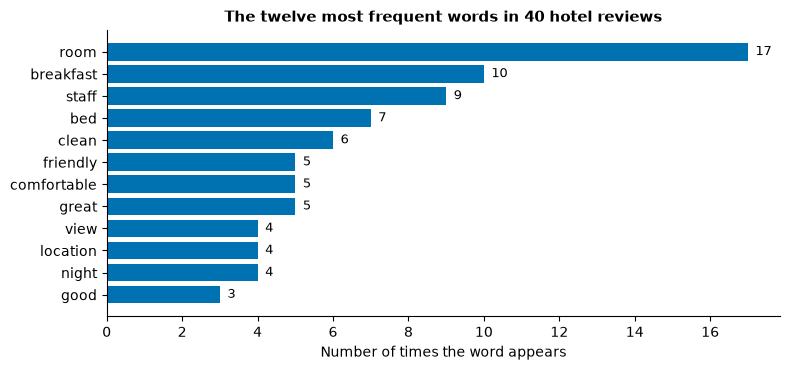

Total words after cleaning: 276  distinct: 169


In [9]:
DOMAIN_STOP = {"hotel", "stay", "would"}
topic_stop = english_stop | DOMAIN_STOP

reviews["tokens"] = reviews["text"].apply(lambda t: clean_tokens(t, topic_stop))
all_words = [w for toks in reviews["tokens"] for w in toks]
freq = nltk.FreqDist(all_words)

top = pd.Series(dict(freq.most_common(12)))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(top.index[::-1], top.values[::-1], color=BLUE)
for y, v in enumerate(top.values[::-1]):
    ax.text(v + 0.2, y, str(v), va="center", fontsize=9)
ax.set_xlabel("Number of times the word appears")
ax.set_title("The twelve most frequent words in 40 hotel reviews")
plt.tight_layout()
plt.show()
print("Total words after cleaning:", len(all_words), " distinct:", len(freq))

Frequency answers **"what do people talk about?"**, not **"what do they think about it?"**. A word near the top may be praised in some reviews and criticised in others. Frequency also counts **mentions, not reviewers**: one long review that repeats a word five times counts five times. A safer count for a manager is often the **number of reviews that mention the word** (document frequency):

In [10]:
doc_freq = Counter(w for toks in reviews["tokens"] for w in set(toks))
compare = pd.DataFrame({"times mentioned": pd.Series(dict(freq.most_common(8))),
                        "reviews mentioning": pd.Series(doc_freq)}).dropna().astype(int)
compare["share of reviews"] = (compare["reviews mentioning"] / len(reviews)).map("{:.0%}".format)
compare

,times mentioned,reviews mentioning,share of reviews
bed,7,7,18%
breakfast,10,10,25%
clean,6,6,15%
comfortable,5,5,12%
friendly,5,5,12%
great,5,3,8%
room,17,17,42%
staff,9,9,22%


### N-grams

Single words lose context. An **n-gram** is a run of *n* consecutive tokens: bigrams (*n* = 2) and trigrams (*n* = 3). "Thin" alone is ambiguous; **"paper thin"** and **"walls thin"** are not. Bigrams are often where the **actionable phrases** live: a product name, a part of the service, a complaint.

> **Predict, then run.** Will the bigram list be more or less useful than the word list for a hotel manager? Which pipeline should feed it: the one that drops "not", or the one that keeps it?

In [11]:
reviews["opinion_tokens"] = reviews["text"].apply(clean_keep_negation)

bigrams = Counter()
for toks in reviews["opinion_tokens"]:
    bigrams.update(nltk.bigrams(toks))     # bigrams within one review, never across two

print("Most common bigrams (negations kept):")
for (w1, w2), n in bigrams.most_common(12):
    print(f"  {w1 + ' ' + w2:<22} {n}")

print("\nBigrams that start with 'not':")
print(sorted(" ".join(b) for b in bigrams if b[0] == "not"))

Most common bigrams (negations kept):
  comfortable bed        3
  room small             3
  staff friendly         2
  friendly staff         2
  bed comfortable        2
  comfortable room       2
  staff helpful          2
  not work               2
  would not              2
  room clean             2
  lovely stay            1
  stay staff             1

Bigrams that start with 'not':
['not advertised', 'not clean', 'not close', 'not stay', 'not work']


The `not …` bigrams exist only because we kept the negations. With small data, most bigrams appear once; with thousands of reviews, the frequent bigrams become a quick list of the issues customers name in their own words.

> **Note:** build n-grams **within** each document. Joining all reviews into one long string first, as quick scripts often do, creates false bigrams across the boundary (the last word of one review followed by the first word of the next). With ten reviews the effect is tiny; with the n-grams of a large corpus it adds noise.

---

## Part 5: Word clouds and their limits (core)

A word cloud draws each word with a size proportional to its frequency. It is popular because it is quick and attractive.

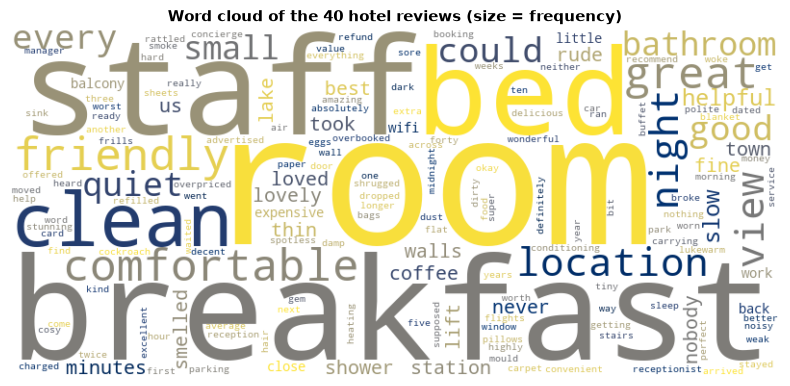

In [12]:
cloud = WordCloud(width=800, height=360, background_color="white", colormap="cividis",
                  random_state=0).generate_from_frequencies(freq)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.imshow(cloud, interpolation="bilinear")
ax.axis("off")
ax.set_title("Word cloud of the 40 hotel reviews (size = frequency)")
plt.show()

Now compare it with the bar chart in Part 4, using what you learned on Day 2 about how accurately people read encodings.

| Question | Word cloud | Sorted bar chart |
|---|---|---|
| Which word is most frequent? | Usually visible | Obvious |
| Is word 3 more frequent than word 4? | Hard: size is **area**, a weak encoding, and long words look bigger | Easy: **length** on a common scale |
| Exact counts? | No | Yes, with labels |
| Positive or negative? | No (colour is usually decorative) | No, unless you split the bars by sentiment |
| Context ("not clean")? | No | No (use bigrams) |
| Same picture each run? | Only with a fixed `random_state` | Yes |

A word cloud is fine as a **first look** or a slide decoration. For a claim in a report ("breakfast is mentioned in a quarter of reviews"), use a sorted bar chart or a table, and quote the count. When you use a cloud, say what it shows ("size = frequency after removing stop words") and check its claims against the counts.

---

## Part 6: How VADER scores text (core)

Sentiment analysis gives each text a score for how positive or negative it is. There are two families:

- **Lexicon-based** methods look words up in a dictionary of pre-rated words and combine the ratings with rules. No training data is needed.
- **Machine-learning** methods learn which words and phrases predict a label from many **labelled** examples (Part 12).

**VADER** (*Valence Aware Dictionary and sEntiment Reasoner*; Hutto and Gilbert, 2014) is a lexicon method designed for short, informal text such as reviews and social posts. Its dictionary holds about 7,500 words, slang terms and emoticons, each rated by human judges from −4 (most negative) to +4 (most positive).

In [13]:
vader = SentimentIntensityAnalyzer()
print("Words in VADER's lexicon:", len(vader.lexicon))
for w in ["excellent", "friendly", "good", "okay", "fine", "slow", "rude", "dirty", "worst",
          "lukewarm", "tiny", "mould"]:
    print(f"  {w:<10} {vader.lexicon.get(w, 'not in lexicon')}")

Words in VADER's lexicon: 7502
  excellent  2.7
  friendly   2.2
  good       1.9
  okay       0.9
  fine       0.8
  slow       not in lexicon
  rude       -2.0
  dirty      -1.9
  worst      -3.1
  lukewarm   not in lexicon
  tiny       not in lexicon
  mould      not in lexicon


`polarity_scores()` returns four numbers. `neg`, `neu` and `pos` are the **shares** of the text that are negative, neutral and positive (they add up to 1). `compound` is the summary score: VADER adds up the adjusted ratings of the words it found and squashes the sum into −1 to +1 with

> **compound = s ÷ √(s² + 15)**,

where *s* is the sum. One positive word moves the score a lot; each further positive word moves it less, so the score approaches 1 but never reaches it.

VADER then adjusts the word ratings with **rules**:

| Rule | Example | Effect |
|---|---|---|
| Negation | "not good" | A negation in the three words before a rated word flips and shrinks its rating |
| Intensifiers (booster words) | "very good", "kind of good" | "very" increases, "kind of" decreases the rating |
| Capitals | "GOOD" in otherwise lower-case text | Increases the rating |
| Exclamation marks | "good!!!" | Increase the score (up to four count) |
| "But" | "good, but terrible" | Words **after** "but" weigh more, words before it less |
| Emoticons and slang | ":)", "lol" | Rated in the lexicon like words |

> **Predict, then run.** For each sentence below, predict the sign of `compound` (+, 0 or −) and whether it will be larger or smaller than for "The coffee is good." Pay special attention to the two "but" sentences and to "isn't bad".

In [14]:
sentences = [
    "The coffee is good.",
    "The coffee is very good.",
    "The coffee is kind of good.",
    "The coffee is GOOD.",
    "The coffee is good!!!",
    "The coffee is not good.",
    "The coffee isn't bad.",
    "The coffee is good, but the service is terrible.",
    "The coffee is terrible, but the service is good.",
    "Not bad at all :)",
]
rules = pd.DataFrame([{"sentence": s, **vader.polarity_scores(s)} for s in sentences])
rules.set_index("sentence")[["neg", "neu", "pos", "compound"]]

,neg,neu,pos,compound
sentence,,,,
The coffee is good.,0.000,0.508,0.492,0.4404
The coffee is very good.,0.000,0.556,0.444,0.4927
The coffee is kind of good.,0.000,0.657,0.343,0.3832
The coffee is GOOD.,0.000,0.452,0.548,0.5622
The coffee is good!!!,0.000,0.443,0.557,0.5826
The coffee is not good.,0.376,0.624,0.000,-0.3412
The coffee isn't bad.,0.000,0.513,0.487,0.4310
"The coffee is good, but the service is terrible.",0.317,0.534,0.149,-0.4939
"The coffee is terrible, but the service is good.",0.159,0.543,0.298,0.4215


Check your predictions:

- **Intensifiers, capitals and "!!!"** all push the score away from zero; "kind of" pulls it towards zero.
- **"not good"** flips the sign. **"isn't bad"** becomes mildly positive: VADER handles simple double negatives.
- The **two "but" sentences** contain the same words, yet get opposite signs: what comes after "but" dominates, as it does for a human reader.

### From score to label

To report counts, the compound score is usually cut into three labels with the thresholds recommended by VADER's authors:

| Compound score | Label |
|---|---|
| ≥ 0.05 | Positive |
| between −0.05 and 0.05 | Neutral |
| ≤ −0.05 | Negative |

The thresholds are a **convention**, not a law. A score of 0.04 and a score of 0.06 are almost the same, yet get different labels. Part 8 shows how much the counts depend on them.

In [15]:
def sentiment_label(score, cut=0.05):
    if score >= cut:
        return "Positive"
    if score <= -cut:
        return "Negative"
    return "Neutral"

reviews["compound"] = reviews["text"].apply(lambda t: vader.polarity_scores(t)["compound"])
reviews["vader_label"] = reviews["compound"].apply(sentiment_label)
reviews[["review_id", "stars", "text", "compound", "vader_label"]].head(8)

,review_id,stars,text,compound,vader_label
0,1,5,Lovely stay! The staff were friendly and the breakfast was excellent.,0.8999,Positive
1,2,4,Clean room and a comfortable bed. Breakfast was good but the coffee was weak.,0.0258,Neutral
2,3,1,The room was tiny and the walls were paper thin. We heard every word next door.,0.0000,Neutral
3,4,2,"Check-in took forty minutes. The receptionist was polite, but nobody could find our booking.",0.0000,Neutral
4,5,5,Best hotel we have stayed in this year. Amazing view of the lake and a really comfortable bed.,0.9117,Positive
5,6,1,"Great, the lift broke again. Loved carrying our bags up five flights of stairs.",0.7351,Positive
6,7,3,"The room was fine. No frills at all, but the location is convenient for the station.",-0.0516,Negative
7,8,2,The shower was lukewarm every morning and the air conditioning rattled all night.,0.0000,Neutral


---

## Part 7: Where VADER fails (core)

A lexicon only knows the words in it and the rules it was given. Predict what happens to each sentence below, then run.

In [16]:
hard_cases = {
    "Domain words not in the lexicon": "The shower was lukewarm and the room was tiny.",
    "Complaint as a fact, no opinion word": "I waited 45 minutes for a table.",
    "Sarcasm": "Great, another cold shower. Just what I wanted.",
    "Slang with a positive meaning": "That concert was sick!",
    "Double negative with an unknown word": "The staff were not unhelpful.",
    "Mixed review, praise first": "Lovely staff and a great view, but the bathroom had mould.",
}
pd.DataFrame([{"failure type": k, "sentence": s, "compound": vader.polarity_scores(s)["compound"]}
              for k, s in hard_cases.items()])

,failure type,sentence,compound
0,Domain words not in the lexicon,The shower was lukewarm and the room was tiny.,0.0000
1,"Complaint as a fact, no opinion word",I waited 45 minutes for a table.,0.0000
2,Sarcasm,"Great, another cold shower. Just what I wanted.",0.6249
3,Slang with a positive meaning,That concert was sick!,-0.5562
4,Double negative with an unknown word,The staff were not unhelpful.,0.0000
5,"Mixed review, praise first","Lovely staff and a great view, but the bathroom had mould.",0.6059


The patterns behind these failures:

| Failure | Why | What helps |
|---|---|---|
| **Domain vocabulary** ("lukewarm", "tiny", "mould", "overbooked") | Not in a general-purpose lexicon, so rated 0 | Add domain words to the lexicon with care, or train a model on labelled domain text |
| **Facts that imply a complaint** ("waited 45 minutes", "charged twice") | No opinion words at all | Topic or keyword rules; machine learning with labels |
| **Sarcasm and irony** | Positive words with a negative meaning | Very hard for any method; human review of a sample |
| **Slang and new meanings** ("sick", "killer") | The lexicon rates the dictionary meaning | Update the lexicon; models trained on recent text |
| **Mixed reviews** | One number cannot hold "great staff, mouldy bathroom" | Score each sentence or each **aspect** separately |
| **Other languages, code-switching, emoji** | Lexicon is English | A tool for that language; translate with care |

The reading packet makes the key point: a neutral score for a clearly negative complaint is a **limitation of the method**, not a bug in your code. The only way to find out how often it happens in **your** data is to check.

> **Misconception:** "A compound score of 0 means the customer was neutral." It often means VADER **found no words it knows**. Look at `neu`: a score of 0 with `neu` = 1.0 is "no opinion words found", which is not the same as "a balanced opinion".

---

## Part 8: Validating scores against labels (core)

Before anyone acts on sentiment scores, compare them with a human judgement on a sample. Here each review has a **star rating**, which we can turn into a reference label: 4–5 stars positive, 3 neutral, 1–2 negative. (Stars are not perfect either: some people write a glowing review and give 3 stars, but they are the customer's own judgement.)

> **Predict, then run.** Out of 40 reviews, how many do you expect VADER's label to agree with the star label? 35? 30? 25?

In [17]:
def star_label(stars):
    return "Positive" if stars >= 4 else ("Negative" if stars <= 2 else "Neutral")

reviews["star_label"] = reviews["stars"].apply(star_label)
order = ["Negative", "Neutral", "Positive"]
confusion = pd.crosstab(reviews["star_label"], reviews["vader_label"],
                        rownames=["Stars say"], colnames=["VADER says"]).reindex(index=order, columns=order, fill_value=0)
print(confusion)
agree = (reviews["star_label"] == reviews["vader_label"]).mean()
print(f"\nAgreement: {agree:.0%} of reviews")

VADER says  Negative  Neutral  Positive
Stars say                              
Negative           5        9         3
Neutral            2        0         5
Positive           0        1        15

Agreement: 50% of reviews


This table is a **confusion matrix**: rows are the reference labels, columns are the scorer's labels, and the diagonal holds the agreements. Read it row by row. The positive reviews are mostly recognised. The **negative** reviews are where VADER struggles: many of the 1–2 star reviews land in Neutral or even Positive. That is the dangerous direction for a business, because those are the customers it most needs to hear.

Look at the disagreements themselves; the reason is usually visible in one reading.

In [18]:
missed = reviews[(reviews["star_label"] == "Negative") & (reviews["vader_label"] != "Negative")]
missed[["review_id", "stars", "compound", "vader_label", "text"]]

,review_id,stars,compound,vader_label,text
2,3,1,0.0000,Neutral,The room was tiny and the walls were paper thin. We heard every word next door.
3,4,2,0.0000,Neutral,"Check-in took forty minutes. The receptionist was polite, but nobody could find our booking."
5,6,1,0.7351,Positive,"Great, the lift broke again. Loved carrying our bags up five flights of stairs."
7,8,2,0.0000,Neutral,The shower was lukewarm every morning and the air conditioning rattled all night.
9,10,1,0.0000,Neutral,Never again. The bathroom had mould and the sheets smelled of smoke.
17,18,2,0.0000,Neutral,"The wifi dropped every ten minutes, so I could not work from the room."
19,20,1,0.0000,Neutral,Overbooked. They moved us to another hotel across town at midnight.
21,22,2,0.2235,Positive,The room was not as advertised. No balcony and the view was a car park.
29,30,1,0.0000,Neutral,Cockroach in the bathroom on the first night. Reception just shrugged.
31,32,2,0.0000,Neutral,Breakfast ran out of eggs by 8am and nobody refilled the coffee.


Most of these use words from Part 7's failure list: domain words ("tiny", "lukewarm", "mould", "overbooked"), facts that imply a complaint ("charged", "waited", "moved us"), and sarcasm.

Two more useful numbers come from the matrix. Of the reviews that **are** negative (by stars), what share did VADER catch? That is **recall** for the negative class. Of the reviews VADER **called** negative, what share really were? That is **precision**.

In [19]:
is_neg = reviews["star_label"] == "Negative"
called_neg = reviews["vader_label"] == "Negative"
recall = (is_neg & called_neg).sum() / is_neg.sum()
precision = (is_neg & called_neg).sum() / called_neg.sum()
print(f"Negative reviews by stars: {is_neg.sum()},  called negative by VADER: {called_neg.sum()}")
print(f"Recall for negative (share of unhappy guests caught):     {recall:.0%}")
print(f"Precision for negative (share of flags that were right):  {precision:.0%}")

print("\nHow the label counts change with the threshold:")
for cut in [0.01, 0.05, 0.20, 0.50]:
    counts = reviews["compound"].apply(sentiment_label, cut=cut).value_counts().reindex(order, fill_value=0)
    print(f"  cut = {cut:<5} " + "  ".join(f"{k}: {v:>2}" for k, v in counts.items()))

Negative reviews by stars: 17,  called negative by VADER: 7
Recall for negative (share of unhappy guests caught):     29%
Precision for negative (share of flags that were right):  71%

How the label counts change with the threshold:
  cut = 0.01  Negative:  7  Neutral:  9  Positive: 24
  cut = 0.05  Negative:  7  Neutral: 10  Positive: 23
  cut = 0.2   Negative:  5  Neutral: 13  Positive: 22
  cut = 0.5   Negative:  2  Neutral: 24  Positive: 14


The share of "negative" reviews in a report can change a lot with the threshold, and the threshold was never chosen for this business. A validation step therefore answers three questions: **How often does the scorer agree with people? Where does it disagree? Which threshold suits the decision?**

> **Misconception:** "The tool is published and widely used, so its scores are accurate." It is accurate **on the kind of text it was built and tested on**. Your domain may differ. Validate on a few hundred hand-labelled examples from your own data before you report percentages.

The same logic applies to anything a model scores: a fraud score, a churn risk, a CV-screening score. A score you have not checked against reality is an opinion with decimals.

---

## Part 9: From scores to decisions (core)

A sentiment distribution ("55% positive") is a **finding**. A manager needs a **decision**: what to fix, where, and how to tell whether it worked. Three tools help.

### 1. Combine topic and sentiment (aspects)

Group words into the **aspects** a manager can act on, then ask, for each aspect: how many reviews mention it, and how unhappy are those reviewers?

In [20]:
ASPECTS = {
    "staff":       {"staff", "receptionist", "manager", "reception", "concierge", "service"},
    "cleanliness": {"clean", "dirty", "mould", "dust", "hair", "cockroach", "spotless", "damp", "smelled"},
    "breakfast":   {"breakfast", "coffee", "eggs", "food", "buffet"},
    "noise":       {"noisy", "quiet", "heard", "thin", "rattled"},
    "bed":         {"bed", "pillows", "sleep", "blanket"},
    "booking and billing": {"booking", "overbooked", "charged", "refund", "waited", "check-in"},
    "facilities":  {"wifi", "lift", "shower", "heating", "parking", "window", "air"},
}
lower_tok = reviews["text"].str.lower().apply(word_tokenize)
rows = []
for aspect, words in ASPECTS.items():
    hit = lower_tok.apply(lambda toks: bool(words & set(toks)))
    sub = reviews[hit]
    rows.append({"aspect": aspect, "reviews": len(sub),
                 "share 1-2 stars": (sub["stars"] <= 2).mean(),
                 "share VADER negative": (sub["vader_label"] == "Negative").mean(),
                 "mean stars": sub["stars"].mean()})
aspects = pd.DataFrame(rows).set_index("aspect").sort_values("share 1-2 stars", ascending=False)
shown = aspects.copy()
for col in ["share 1-2 stars", "share VADER negative"]:
    shown[col] = shown[col].map("{:.0%}".format)
shown.round(1)

,reviews,share 1-2 stars,share VADER negative,mean stars
aspect,,,,
booking and billing,6,67%,33%,2.3
facilities,8,62%,0%,2.5
cleanliness,11,45%,18%,2.8
bed,9,44%,33%,3.0
noise,7,43%,14%,2.9
staff,14,21%,14%,3.6
breakfast,11,9%,0%,4.2


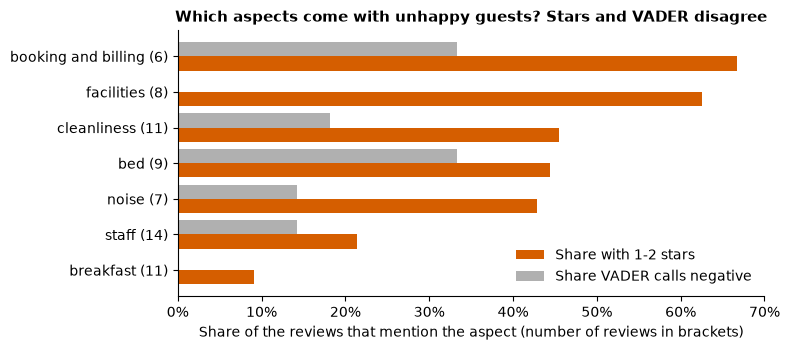

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(aspects))
ax.barh(y + 0.2, aspects["share 1-2 stars"], height=0.4, color=ORANGE, label="Share with 1-2 stars")
ax.barh(y - 0.2, aspects["share VADER negative"], height=0.4, color=GREY, label="Share VADER calls negative")
ax.set_yticks(y, [f"{a} ({n})" for a, n in zip(aspects.index, aspects["reviews"])])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Share of the reviews that mention the aspect (number of reviews in brackets)")
ax.set_title("Which aspects come with unhappy guests? Stars and VADER disagree")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

Compare the two bars for each aspect. If the manager ranked the problems by VADER alone, aspects whose complaints use domain words or plain facts (booking and billing, facilities) would look much less serious than the guests' own ratings say. **The method shapes the priority list.** Small counts matter too: an aspect mentioned in four reviews is a lead to investigate, not a conclusion.

### 2. Decide what a score triggers, and count the cost of errors

Suppose the hotel wants to reply personally to every unhappy guest within a day. A rule such as "flag every review VADER calls negative" has two kinds of error:

| Error | Example | Cost |
|---|---|---|
| **Missed complaint** (false negative) | A 1-star review about mould scored neutral | An unhappy guest gets no reply; a public complaint stays unanswered |
| **False alarm** (false positive) | A 3-star review flagged as negative | A few minutes of staff time |

Here a missed complaint costs much more than a false alarm, so the rule should catch more, even at the price of more false alarms: use the **star rating** where it exists, add **keyword rules** for known domain complaints, and send everything with a score below a generous threshold to a person. The threshold is a **business decision** about the cost of each error, not a technical default.

### 3. Write the recommendation

A text-mining recommendation has four parts:

1. **Finding**, with the count and the method: "Of 40 reviews, *n* mention [aspect]; *x*% of those gave 1–2 stars."
2. **Evidence** a manager can read: two or three short quotes (anonymised).
3. **Action** with an owner: "Facilities manager to check [item] at [site] by [date]."
4. **How we will know**: the measure to watch afterwards (share of reviews mentioning the aspect, mean stars) and **its limit** ("the scorer misses complaints worded as facts, so we read a sample by hand each month").

---

## Part 10: Stemming and lemmatisation (extension)

"room" and "rooms", "help", "helped", "helpful" and "helping": should they count as one word? Two ways to reduce words to a common form:

| | Stemming | Lemmatisation |
|---|---|---|
| How | Chops endings with fixed rules | Looks the word up in a dictionary, often using its part of speech |
| Output | A **stem**, which may not be a real word (`comfort`, `friendli`) | A **lemma**, a real dictionary word (`be` for "was", `good` for "better") |
| Speed and needs | Fast; no data needed | Slower; needs a dictionary such as WordNet |
| Risk | Over-stemming (`university`, `universe` → `univers`) and under-stemming | Needs the right part of speech ("meeting" the noun vs "meeting" the verb) |

The Porter stemmer needs no data, so we can try it offline:

In [22]:
stemmer = PorterStemmer()
words = ["room", "rooms", "help", "helped", "helpful", "helping", "comfortable", "comfort",
         "friendly", "friendliness", "was", "better", "university", "universe", "news", "new"]
pd.DataFrame({"word": words, "Porter stem": [stemmer.stem(w) for w in words]}).set_index("word").T

word,room,rooms,help,helped,helpful,helping,comfortable,comfort,friendly,friendliness,was,better,university,universe,news,new
Porter stem,room,room,help,help,help,help,comfort,comfort,friendli,friendli,wa,better,univers,univers,news,new


Stemming merges `help`, `helped` and `helping` (good) and turns `friendly` into `friendli` (ugly but harmless for counting). It cannot know that `was` is a form of `be` (it even cuts it to `wa`) or that `better` is a form of `good`; a **lemmatiser** can, because it uses a dictionary (NLTK's `WordNetLemmatizer` needs the WordNet data, which this course's bundle does not include, so we do not run it here). It merges `university` and `universe` and `news` and `new` (bad: different meanings).

When to use them: for **counting topics** in large collections, stemming or lemmatising reduces the vocabulary and merges obvious variants. For **sentiment with VADER**, do **not**: VADER's lexicon expects real words, and `comfort` or `friendli` may not be in it. Also note that `helpful` and `helping` carry different opinions; merging them can blur the signal.

---

## Part 11: TF-IDF (extension)

Raw counts favour words that are common **everywhere** ("room" appears in many reviews, so it tells you little about any one of them). **TF-IDF** (term frequency × inverse document frequency) scores a word highly in a document when it is **frequent in that document** but **rare across the collection**:

> **TF-IDF of word *w* in document *d* = tf(*w*, *d*) × log(*N* ÷ df(*w*))**,

where tf is the count of word *w* in document *d*, *N* is the number of documents, and df is the number of documents that contain *w*. A word found in every document gets log(*N* ÷ *N*) = log 1 = 0. (Libraries add small adjustments, such as +1 terms, but the idea is the same.)

### By hand, with three tiny documents

> **Predict, then run.** In the three documents below, which word gets a TF-IDF of exactly 0 in every document? Which word gets the highest score in document C?

In [23]:
docs = {"A": "room clean room quiet",
        "B": "room noisy staff rude",
        "C": "room cockroach cockroach staff"}
N = len(docs)
vocab = sorted({w for d in docs.values() for w in d.split()})
df_w = {w: sum(w in d.split() for d in docs.values()) for w in vocab}
table = pd.DataFrame({name: {w: d.split().count(w) * np.log(N / df_w[w]) for w in vocab}
                      for name, d in docs.items()}).round(2)
table["documents containing"] = pd.Series(df_w)
table

,A,B,C,documents containing
clean,1.1,0.00,0.00,1
cockroach,0.0,0.00,2.20,1
noisy,0.0,1.10,0.00,1
quiet,1.1,0.00,0.00,1
room,0.0,0.00,0.00,3
rude,0.0,1.10,0.00,1
staff,0.0,0.41,0.41,2


"room" is in all three documents, so its weight is 0 everywhere, however often it appears. "cockroach" is in one document and appears twice there, so it dominates document C. TF-IDF picks out what is **distinctive** about each document.

### On the reviews

scikit-learn's `TfidfVectorizer` does the counting, weighting and normalising in one step. A useful question for a manager: which words are most **distinctive of the unhappy reviews**? We average each word's TF-IDF over the 1–2 star reviews and over the 4–5 star reviews and compare.

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words=sorted(opinion_stop), token_pattern=r"[a-z]+(?:-[a-z]+)?")
X = tfidf.fit_transform(reviews["text"].str.lower())
weights = pd.DataFrame(X.toarray(), columns=tfidf.get_feature_names_out())

low = weights[reviews["stars"] <= 2].mean()
high = weights[reviews["stars"] >= 4].mean()
distinct = pd.DataFrame({"mean TF-IDF, 1-2 stars": low, "mean TF-IDF, 4-5 stars": high})
distinct["difference"] = distinct.iloc[:, 0] - distinct.iloc[:, 1]
print("Most distinctive of the unhappy reviews:")
print(distinct.sort_values("difference", ascending=False).head(8).round(3))
print("\nMost distinctive of the happy reviews:")
print(distinct.sort_values("difference").head(8).round(3))

Most distinctive of the unhappy reviews:
          mean TF-IDF, 1-2 stars  mean TF-IDF, 4-5 stars  difference
not                        0.084                     0.0       0.084
night                      0.055                     0.0       0.055
every                      0.054                     0.0       0.054
never                      0.044                     0.0       0.044
smelled                    0.044                     0.0       0.044
bathroom                   0.042                     0.0       0.042
work                       0.042                     0.0       0.042
nobody                     0.042                     0.0       0.042

Most distinctive of the happy reviews:
             mean TF-IDF, 1-2 stars  mean TF-IDF, 4-5 stars  difference
staff                         0.000                   0.121      -0.121
breakfast                     0.015                   0.131      -0.115
friendly                      0.000                   0.090      -0.090
comfortabl

The unhappy reviews are distinguished by **negations** (*not*, *never*, *nobody*) and **descriptions** of what happened (*smelled*, *bathroom*, *night*, *work*), the happy ones by **evaluative** words (*friendly*, *comfortable*, *lovely*) and the things guests liked (*staff*, *breakfast*). Note *slow* on the happy side: mild complaints sit inside 4-star reviews too. That is one more reason a pure sentiment lexicon misses complaints: unhappy guests often **describe** rather than **evaluate**. TF-IDF is also the usual way to turn text into numeric **features** for a model, the topic of Day 4.

---

## Part 12: Lexicon or machine learning? (extension)

| | Lexicon (VADER) | Machine learning (for example, logistic regression on TF-IDF) |
|---|---|---|
| Needs labelled data | No | Yes, usually hundreds to thousands of examples |
| Transparent | Yes: you can see which words scored | Partly: you can inspect word weights |
| Domain vocabulary | Only if you add it | Learns it from the labels |
| Speed to start | Minutes | Days to weeks (labelling) |
| Typical accuracy in a specific domain | Moderate | Higher, if the labels are good and plentiful |
| Main risk | Misses domain words and sarcasm | Learns the biases and errors in its labels; drifts as language changes |

Modern large language models are a third option. They handle context and sarcasm better, but are harder to audit, cost more per document, and still need to be **validated** on your labels in exactly the same way.

A tiny demonstration: train a classifier to spot 1–2 star reviews from their words, and test it fairly with **leave-one-out** validation (train on 39 reviews, predict the 40th, repeat 40 times).

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline

y = (reviews["stars"] <= 2).astype(int)        # 1 = unhappy guest
model = make_pipeline(TfidfVectorizer(token_pattern=r"[a-z]+(?:-[a-z]+)?"), LogisticRegression(C=10))
pred = cross_val_predict(model, reviews["text"].str.lower(), y, cv=LeaveOneOut())

vader_pred = (reviews["vader_label"] == "Negative").astype(int)
for name, p in [("VADER (negative label)", vader_pred), ("Logistic regression, leave-one-out", pred)]:
    caught = ((p == 1) & (y == 1)).sum()
    print(f"{name:<36} accuracy {np.mean(p == y):.0%}   unhappy guests caught {caught} of {y.sum()}")

VADER (negative label)               accuracy 65%   unhappy guests caught 5 of 17
Logistic regression, leave-one-out   accuracy 60%   unhappy guests caught 5 of 17


With only 40 examples, neither method is trustworthy, and the comparison could easily flip with another 40 reviews. The point is the workflow: a model is only as good as the **amount and quality of labelled data** behind it, and both methods are judged the **same way**, on data the model has not seen. You will meet train/test thinking again in the forecasting lecture and on Day 4.

A middle path is to **extend the lexicon** with domain words. In NLTK, `vader.lexicon` is a dictionary, so `vader.lexicon.update({"lukewarm": -1.5})` changes later scores. That is powerful and risky: whoever picks the ratings decides the results, so record every change, justify it, and re-validate.

---

## Part 13: Ethics of mining customer text (core summary, extension detail)

Customer text is written by people, often about other people, and rarely with analysis in mind. Five questions to ask before mining it:

1. **Consent and purpose.** Did people agree to this use? A review posted to help other travellers is not obviously consent to build a profile of the reviewer. Use the text for the purpose it was collected for, or get consent.
2. **Personal data.** Reviews and support chats contain names, e-mail addresses, phone and room numbers, and sometimes health or family details. Mask them **before** analysis and keep only what you need (data minimisation). In China, the Personal Information Protection Law (PIPL) applies; in Europe, the GDPR.
3. **People named in the text.** Complaints often name staff ("the receptionist, Li, was rude"). Using sentiment scores to judge or discipline individual employees, without context or a chance to respond, is unfair and often unlawful.
4. **Bias.** Lexicons and models work best on the language they were built on. Non-native speakers, dialects, other languages and older or younger customers can be scored systematically differently, so their complaints count for less. Check accuracy **by group**, not only overall.
5. **Manipulation and honesty.** Do not use mining to suppress or bury negative reviews, to target vulnerable customers, or to publish "95% positive" when the scorer misses complaints. Fake reviews also exist; mining them as genuine distorts the decision.

A simple example of masking personal data with regular expressions:

In [26]:
raw = [
    "Room 212 was freezing. Call me on 138-0013-8000 or write to guest.wang@example.com.",
    "Thanks to Ms Chen at reception! My booking ref is LK-55821.",
]
def mask(text):
    text = re.sub(r"[\w.+-]+@[\w-]+\.[\w.]+", "[EMAIL]", text)
    text = re.sub(r"\b\d{3}[- ]?\d{4}[- ]?\d{4}\b", "[PHONE]", text)
    text = re.sub(r"\b[A-Z]{2}-\d{4,}\b", "[BOOKING]", text)
    text = re.sub(r"\b(Mr|Ms|Mrs|Dr)\.? [A-Z][a-z]+", "[NAME]", text)
    return text

for t in raw:
    print(mask(t))

Room 212 was freezing. Call me on [PHONE] or write to [EMAIL]
Thanks to [NAME] at reception! My booking ref is [BOOKING].


Pattern-based masking catches **formats** (e-mails, phone numbers), but misses free-form names ("ask for Li") and room numbers written as words. In practice it is combined with named-entity recognition and a human check of a sample. Masking is a minimum, not a guarantee of anonymity: a review that mentions a date, a site and an unusual event can still identify a guest.

---

## Part 14: Business case (extension)

**A food-delivery platform** collects about 200,000 written restaurant reviews a month. Product managers propose three uses of automatic sentiment scores:

- **A.** Show each restaurant a monthly "sentiment score" next to its star rating.
- **B.** Automatically hide restaurants whose sentiment falls below a threshold from the app's front page.
- **C.** Route every review with a negative score to a support agent, who contacts the customer within 24 hours.

Discuss in groups:

1. For each use, which error matters more: a missed negative or a false alarm? Who bears the cost of each?
2. Which use would you approve first, and what validation would you require before launch (sample size, who labels, which groups to check)?
3. Reviews arrive in Mandarin, Cantonese, English and a mix of all three, with many emoji. What does that do to a lexicon such as VADER, and to the fairness of use B?
4. Restaurant owners discover the scoring rules and start asking customers to "please use the word *excellent*". What happens to the measure? (Recall Goodhart's law from Day 2.)
5. Write the one-sentence limitation you would put under any sentiment chart shown to senior managers.

---

## Part 15: Lab 3 briefing (core)

In Lab 3 (periods 5 and 6) you run the same pipeline on a small set of product reviews: tokenise, remove stop words (including a few product words), draw a word cloud, list the most frequent keywords, score each review with VADER, label it with the ±0.05 thresholds, chart the label counts, and answer questions about what you see.

How today's parts map to the lab:

| Lab step | Lecture part to revisit |
|---|---|
| Downloading or loading NLTK data | Setup cell; the [Lab 3 guide](guides/lab3_text_mining.md), Route B |
| Tokenising, `isalpha()`, stop words, domain stop words | Parts 2 and 3 |
| Word cloud and top keywords | Parts 4 and 5 |
| Compound score and the three labels | Part 6 |
| Explaining a score that disagrees with a human reading | Parts 7 and 8 |
| The recommendation to the product team | Part 9 |

Read your answers **from your own output** and name the table or chart they come from. When a score surprises you, look up the words in `vader.lexicon` before you explain it. The [Lab 3 guide](guides/lab3_text_mining.md) has both routes, checks and known pitfalls.

---

## Part 16: Practice, quiz and summary

### Practice

#### Core

**Core 1.** Write three short hotel reviews of your own: one VADER should score clearly positive, one clearly negative, and one that a person reads as negative but VADER scores as neutral or positive. Score them and explain each result with the rules in Part 6.

**Core 2.** Rebuild the frequency bar chart of Part 4 for the **Old Town** site only, then for **Riverside** only. Which words differ? How many reviews does each chart rest on?

**Core 3.** Using the confusion matrix in Part 8, write two sentences for the hotel manager about how far the VADER labels can be trusted, with numbers.

#### Stretch

**Stretch 1.** Change the threshold in `sentiment_label` to 0.3. Recompute the confusion matrix and the recall for negative reviews. Is the rule better or worse for the "reply to every unhappy guest" decision?

**Stretch 2.** Score each **sentence** of a review separately (split with `nltk.sent_tokenize`) and report the most negative sentence of each review. Which reviews does this help with?

**Stretch 3.** Find the three bigrams that appear only in 1–2 star reviews and at least twice. If there are none, explain why with this little data.

#### Challenge

**Challenge 1.** Make a **copy** of the analyser and add up to eight hotel words to its lexicon with ratings you justify (for example, `lukewarm`, `tiny`, `mould`). Re-run Part 8. How much does agreement improve? Then argue the other side: why is this "tuning on the test data", and how should it be done properly?

**Challenge 2.** Write a function `pipeline_report(texts, stars)` that prints the top 10 words, the top 5 bigrams, the VADER label counts and the confusion matrix against the star labels, for any list of reviews.

**Challenge 3.** Extend the `mask` function to catch room numbers ("room 212") and Chinese mobile numbers written without dashes. Test it on five sentences you write, including two that should **not** be masked.

### Quiz

1. Give two examples each of structured and unstructured business data, and say what each can tell a manager that the other cannot.
2. Put these steps in order: stop-word removal, tokenising, validating, lower-casing, scoring, deciding.
3. Why can removing stop words harm a sentiment analysis? Give an example.
4. What does `isalpha()` do to the token `n't`, and why does that matter?
5. Why are bigrams often more useful to a manager than single words?
6. Name two limits of a word cloud and the chart you would use instead.
7. What does TF-IDF give a weight of zero to, and why?
8. Name four of VADER's rules and give an example sentence for each.
9. A review scores `compound` = 0.0 with `neu` = 1.0. What does that most likely mean?
10. Define recall for the negative class in words a manager understands.
11. Give one reason to prefer a lexicon method and one to prefer a machine-learning method.
12. Name three ethical risks in mining customer reviews and one safeguard for each.

### Summary

| Idea | Remember |
|---|---|
| Unstructured data | Text says **why**; it needs converting into columns before analysis |
| Pipeline | Collect, clean, tokenise, normalise, filter, (reduce), represent, analyse, **validate**, decide |
| Stop words | Fine for topics; **keep negations** for opinion; add domain stop words deliberately |
| Frequency | Counts mentions, not reviewers; report the number of reviews too |
| N-grams | Keep phrases and negations together; build them within each document |
| Word clouds | First look only; use a sorted bar chart for claims |
| TF-IDF | Frequent here, rare elsewhere = distinctive |
| VADER | Lexicon plus rules (negation, boosters, capitals, "!", "but"); compound in −1 to +1; ±0.05 labels are a convention |
| Failures | Domain words, facts, sarcasm, slang, mixed reviews, other languages |
| Validation | Confusion matrix against human labels; recall for the class that matters |
| Decisions | Topic × sentiment; error costs set the rule; finding, evidence, action, measure |
| Ethics | Consent, mask personal data, do not judge named staff, check bias by group, be honest about limits |

**References:** Hutto, C. J., & Gilbert, E. (2014). VADER: A parsimonious rule-based model for sentiment analysis of social media text. *Proceedings of the International AAAI Conference on Web and Social Media*, 8(1), 216–225. Bird, S., Klein, E., & Loper, E. (2009). *Natural language processing with Python*. O'Reilly. Porter, M. F. (1980). An algorithm for suffix stripping. *Program*, 14(3), 130–137. Spärck Jones, K. (1972). A statistical interpretation of term specificity and its application in retrieval. *Journal of Documentation*, 28(1), 11–21. Kapiche (n.d.) and Label Your Data (n.d.), as summarised in Chapter 3 of the reading packet.

**Next:** [Forecasting](D3_lecture_forecasting.md) in period 4, then the [Lab 3 guide](guides/lab3_text_mining.md) and the [Lab 4 guide](guides/lab4_forecasting.md).

---

## For the facilitator

This notebook is the **core path for period P3** of Day 3, after the midterm in P1–P2. Forecasting follows in P4, Lab 3 in P5–P6 and Lab 4 in P7–P8. One period is not enough for everything here, so the parts are marked **core** and **extension**: teach the core in P3, and use the extensions in a later study block (for example the Day 4 period on text as a feature), with faster students during the lab, or as self-study. No Lab 3 answers are given: the lab's reviews are never loaded, and its questions are not answered here.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| P3 | 3 | Setup cell; Part 1: structured vs unstructured | Students may be tired after the exam: start with the `describe()` prediction |
| P3 | 7 | Part 2: pipeline table, tokenising, normalising | Point at what `isalpha()` drops |
| P3 | 5 | Part 3: stop words and "Not clean" | Take the prediction by show of hands |
| P3 | 6 | Parts 4–5: frequency, bigrams, word cloud limits | Ask which chart they would put in a report |
| P3 | 8 | Part 6: VADER and the rule sentences | Students predict signs on paper first, then run |
| P3 | 4 | Part 7: failure cases | Ask for one more failure sentence from the room |
| P3 | 7 | Part 8: confusion matrix, recall, threshold | Collect the 35/30/25 predictions before running |
| P3 | 3 | Part 9 (aspects chart and the four-part recommendation) and Part 13's five questions | Read the recommendation template aloud |
| P3 | 2 | Part 15: Lab 3 briefing | Make sure Route B students have run the setup cell |
| Later | 25 | Extensions: Parts 10–12 (stemming, TF-IDF, lexicon vs machine learning) | Fits Day 4 P3 ("text as a feature") or self-study |
| Later | 20 | Extensions: Part 13 detail and Part 14 business case | Group discussion; good evening or online-week material |
| Self-study | — | Part 16: practice and quiz | Core items first |

If the midterm overruns, cut Part 5 to one sentence ("use the bar chart") and skip the threshold loop in Part 8.